# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _UniTi_ · **Tema:** _Chat Bot de assitência tecnica_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [5]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/Guimaraes-Mendonca/UniTi-ChatBot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [6]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [21]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: UniTi | Tema: UniTi - Chat Bot de Assistência com Tecnologias Acadêmicasr


,intenção,descrição
0,wifi,Ajuda com acesso e configuração da rede Wi-Fi institucional Eduroam.
1,email,Ajuda com acesso e configuração do e-mail institucional.
2,senha,Ajuda com recuperação e alteração de senha do Passaporte UFMS.
3,ava,Ajuda com acesso ao Ambiente Virtual de Aprendizagem.
4,sistemas,Ajuda com acesso e utilização dos sistemas acadêmicos e institucionais.
5,suporte,"Orientações sobre problemas técnicos, VPN e canais de suporte de TI."
6,google_drive,Ajuda com transferência de arquivos e utilização de drives compartilhados do...
7,autenticacao,Ajuda com configuração e utilização da autenticação de dois fatores do Gmail.


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

### 2. Construção e Organização dos Dados

#### 🔨 Descrição da Construção dos Dados
- **Autoria e Coleta de Dados Reais (`coletado`)**: As mensagens humanas foram escritas por estudantes da UFMS através de formulário online (Google Forms). O integrante **Caio Magno** foi o responsável por estruturar a coleta, reunir as respostas e realizar a rotulagem manual da base `respostas_classificadas.csv`.
- **Conjunto de Teste (`teste.csv`)**: Composto 100% por frases de origem humana/coletada (33 frases), garantindo **vazamento zero** em relação ao treino (`vazamento = 0`) e cobrindo todas as intenções.
- **Geração de Dados Sintéticos (`llm`)**: Foram geradas 78 frases de treino via LLM (ChatGPT) a partir de prompts em múltiplos estilos de escrita (formal, informal, com erros ortográficos, ansioso e curto) para expandir o treino. As frases sintéticas foram revisadas pelo grupo, mantendo **40% de origem humana no treino** (acima do mínimo de 20% exigido).
- **Negativos Difíceis (`fora_dominio`)**: A classe foi abastecida com perguntas sobre serviços universitários vizinhos (renovação de livros na biblioteca, cardápio do RU, transporte acadêmico e auxílios), que utilizam vocabulário similar ao de TI para testar a fronteira do classificador de escopo.

---

#### 📝 RELATÓRIO: Tabela Intenção × Origem (Treino e Teste)

##### Tabela do Conjunto de Treino (`treino.csv`)
| Intenção | Coletado | LLM | Total Treino |
| :--- | :---: | :---: | :---: |
| `fora_dominio` | 18 | 20 | **38** |
| `chitchat` | 14 | 10 | **24** |
| `wifi` | 6 | 6 | **12** |
| `sistemas` | 5 | 6 | **11** |
| `email` | 3 | 6 | **9** |
| `senha` | 3 | 6 | **9** |
| `suporte` | 3 | 6 | **9** |
| `autenticacao` | 0 | 6 | **6** |
| `ava` | 0 | 6 | **6** |
| `google_drive` | 0 | 6 | **6** |
| **Total Geral** | **52 (40%)** | **78 (60%)** | **130** |

##### Tabela do Conjunto de Teste (`teste.csv`)
| Intenção | Coletado | LLM | Total Teste |
| :--- | :---: | :---: | :---: |
| `fora_dominio` | 12 | 0 | **12** |
| `chitchat` | 8 | 0 | **8** |
| `wifi` | 3 | 0 | **3** |
| `sistemas` | 3 | 0 | **3** |
| `senha` | 2 | 0 | **2** |
| `email` | 1 | 0 | **1** |
| `suporte` | 1 | 0 | **1** |
| `autenticacao` | 1 | 0 | **1** |
| `ava` | 1 | 0 | **1** |
| `google_drive` | 1 | 0 | **1** |
| **Total Geral** | **33 (100%)** | **0 (0%)** | **33** |

In [8]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  ['1 texto(s) duplicado(s) dentro do arquivo']
Vazamento treino→teste: nenhum


origem,coletado,llm,total
intencao,,,
autenticacao,0,6,6
ava,0,6,6
chitchat,14,10,24
email,3,6,9
fora_dominio,18,20,38
google_drive,0,6,6
senha,3,6,9
sistemas,5,6,11
suporte,3,6,9


origem,coletado,total
intencao,,
autenticacao,1,1
ava,1,1
chitchat,8,8
email,1,1
fora_dominio,12,12
google_drive,1,1
senha,2,2
sistemas,3,3
suporte,1,1


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [9]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
gerados = pd.read_csv("dados/gerados_llm.csv")
gerados.sample(15)

,texto,intencao,origem
1376,Solicitar acesso ao processo,sei,llm
851,o arquivo que mandaram pro drive compartilhado nao aparece pra mim,google_drive,llm
1320,Preciso passar uma pasta grande do meu Drive para o drive compartilhado do g...,google_drive,llm
1122,não to conseguindo entrar no ava da faculdade,ava,llm
95,Configuração do Outlook universitário,email,llm
1026,Como configuro o e-mail da faculdade no Outlook?,email,llm
1037,meu email da uni nao carrega as mensagens no celular,email,llm
296,Abrir chamado técnico,suporte,llm
1400,o app autenticador nao ta gerando codigo valido pra entrar no gmail,autenticacao,llm
177,nao aparece a materia que comecei essa semana no ambiente virtual,ava,llm


🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [10]:
# 🔨 TODO: Análise exploratória
import pandas as pd
import numpy as np
from collections import Counter
import os

# 1. Carregar dados de treino
path_treino = "dados/treino.csv" if os.path.exists("dados/treino.csv") else "treino.csv"
df_treino = pd.read_csv(path_treino)

# 2. Métricas de tamanho das mensagens
df_treino["qtd_palavras"] = df_treino["texto"].astype(str).apply(lambda x: len(x.split()))
df_treino["qtd_caracteres"] = df_treino["texto"].astype(str).str.len()

print("=== 1. TAMANHO DAS MENSAGENS POR CLASSE (MÉDIA E MEDIANA) ===")
tamanho_por_classe = df_treino.groupby("intencao")["qtd_palavras"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print(tamanho_por_classe)

print("\n=== 2. DIFERENÇAS ENTRE FRASES HUMANAS (COLETADO) E LLM ===")
tamanho_por_origem = df_treino.groupby("origem")["qtd_palavras"].agg(["count", "mean", "median", "std"]).round(2)
print(tamanho_por_origem)

print("\n=== 3. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (EXCLUINDO STOPWORDS) ===")
stopwords_pt = set(["a", "ao", "aos", "as", "até", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "esta", "está", "eu", "foi", "isso", "já", "mais", "mas", "me", "meu", "minha", "na", "nas", "no", "nos", "o", "os", "ou", "para", "pela", "pelo", "por", "qual", "quando", "que", "quem", "se", "sem", "ser", "sua", "tem", "um", "uma", "você", "pra", "oq", "pq", "ter", "tenho"])

for intencao, grp in df_treino.groupby("intencao"):
    palavras = []
    for txt in grp["texto"]:
        tokens = [w.lower().strip("?,!.:;") for w in txt.split() if w.lower().strip("?,!.:;") not in stopwords_pt and len(w) > 2]
        palavras.extend(tokens)
    top_words = Counter(palavras).most_common(5)
    print(f"• {intencao:15s}: {', '.join([f'{w}({c})' for w, c in top_words])}")

print("\n=== 4. EXEMPLOS DE NEGATIVOS DIFÍCEIS (fora_dominio) ===")
negativos_dificeis = df_treino[df_treino["intencao"] == "fora_dominio"]["texto"].head(5).tolist()
for i, ex in enumerate(negativos_dificeis, 1):
    print(f"{i}. \"{ex}\"")

=== 1. TAMANHO DAS MENSAGENS POR CLASSE (MÉDIA E MEDIANA) ===
              count   mean  median   std  min  max
intencao                                          
autenticacao      6   9.50     9.0  1.38    8   12
ava               6  10.33    10.5  0.82    9   11
chitchat         24   5.08     5.0  2.64    1   12
email             9  11.11    10.0  2.85    9   18
fora_dominio     38   9.18     9.0  2.93    2   18
google_drive      6  10.67    11.0  0.52   10   11
senha             9   9.33    10.0  1.50    7   11
sistemas         11   8.91     9.0  2.02    6   13
suporte           9  11.44    11.0  1.51    9   14
wifi             12  10.50     9.0  5.18    6   26

=== 2. DIFERENÇAS ENTRE FRASES HUMANAS (COLETADO) E LLM ===
          count  mean  median   std
origem                             
coletado     52  8.52     8.0  4.73
llm          78  9.26    10.0  1.95

=== 3. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (EXCLUINDO STOPWORDS) ===
• autenticacao   : login(2), primeiro(2), autenti

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [12]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    # 🔨 TODO: outras variações (ex.: com stopwords, só unigramas, embeddings...)
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.



In [13]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

from chatbot.config import carregar_config
from chatbot.dados import carregar_dados, adicionar_escopo
from chatbot.representacoes import tfidf_palavras, tfidf_caracteres

# 1. Configurações e semente de aleatoriedade
config = carregar_config("grupo.yaml")
treino = adicionar_escopo(carregar_dados(config.treino), config)

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Representações e Classificadores a serem testados
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
}

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000, random_state=RANDOM_STATE),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600, random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
}

# 3. Função de comparação
def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"], return_train_score=True, n_jobs=-1)
            linhas.append({
                "representação": nome_rep,
                "classificador": nome_clf,
                "F1 macro (CV)": r["test_f1_macro"].mean(),
                "desvio": r["test_f1_macro"].std(),
                "acurácia (CV)": r["test_accuracy"].mean(),
                "F1 macro (treino)": r["train_f1_macro"].mean()
            })
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)

# 4. Execução da comparação no escopo
tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Rede neural (MLP),0.719,0.121,0.777,1.0
1,TF-IDF palavras,Rede neural (MLP),0.709,0.168,0.762,1.0
2,TF-IDF caracteres,Regressão logística,0.676,0.162,0.746,1.0
3,TF-IDF palavras,Regressão logística,0.663,0.175,0.731,1.0
4,TF-IDF palavras,Árvore de decisão,0.572,0.091,0.615,1.0
5,TF-IDF caracteres,Árvore de decisão,0.563,0.112,0.585,1.0


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [14]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()), 
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", 
    cv=cv, 
    n_jobs=-1
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

{'classificador__C': 100} 0.718


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

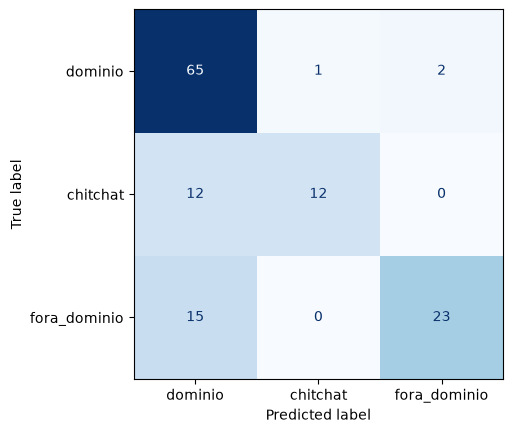

,texto,escopo,previsto,origem
1,Aoba…,chitchat,dominio,coletado
2,"Chatbot, você está aí?",chitchat,dominio,coletado
3,"""Como eu faço tal coisa...""",chitchat,dominio,coletado
4,Começaria com a minha pergunta direto. Mas se tiver que escolher: oi,chitchat,dominio,coletado
5,Eae,chitchat,dominio,coletado
6,pode me ajudar?,chitchat,dominio,coletado
9,Ei\r\nMe ajuda a resolver tal problema…,chitchat,dominio,coletado
11,"""oi chat, vc pode conversar cmg ?""",chitchat,dominio,coletado
21,qual melhor forma de entrar no mercaod de trabalho?,fora_dominio,dominio,coletado
22,qual melhor serie pra maratonar?,fora_dominio,dominio,coletado


In [15]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [16]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Rede neural (MLP),0.579,0.128,0.647,1.0
1,TF-IDF palavras,Regressão logística,0.564,0.135,0.631,1.0
2,TF-IDF caracteres,Regressão logística,0.562,0.204,0.673,1.0
3,TF-IDF palavras,Rede neural (MLP),0.539,0.153,0.614,1.0
4,TF-IDF palavras,Árvore de decisão,0.491,0.099,0.531,1.0
5,TF-IDF caracteres,Árvore de decisão,0.397,0.050,0.425,1.0


In [17]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()), 
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", 
    cv=cv, 
    n_jobs=-1
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_  # <--- É aqui que a variável é criada!

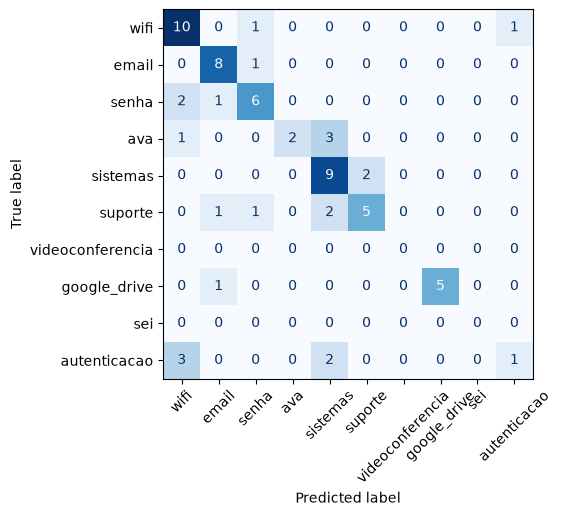

              precision    recall  f1-score   support

autenticacao       0.50      0.17      0.25         6
         ava       1.00      0.33      0.50         6
       email       0.73      0.89      0.80         9
google_drive       1.00      0.83      0.91         6
       senha       0.67      0.67      0.67         9
    sistemas       0.56      0.82      0.67        11
     suporte       0.71      0.56      0.62         9
        wifi       0.62      0.83      0.71        12

    accuracy                           0.68        68
   macro avg       0.72      0.64      0.64        68
weighted avg       0.70      0.68      0.66        68



In [18]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [19]:
# 🔨 TODO
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict

# 1. Obter probabilidades via validação cruzada (5 folds) no treino do domínio
probas_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv, method="predict_proba")
max_probas = probas_tema.max(axis=1)

# 2. Identificar acertos e erros
prevs_tema = clf_tema.classes_[probas_tema.argmax(axis=1)]
corretos = (prevs_tema == treino_dom["intencao"].values)

print("=== DISTRIBUIÇÃO DE CONFIANÇA DO MODELO DE TEMA ===")
print(f"Média de confiança nos ACERTOS: {max_probas[corretos].mean():.2%}")
print(f"Média de confiança nos ERROS:   {max_probas[~corretos].mean():.2%}")

# 3. Simulação de diferentes limiares
print("\n=== SIMULAÇÃO DE IMPACTO DO LIMIAR ===")
for limiar in [0.20, 0.25, 0.30, 0.35, 0.40]:
    aceitos = max_probas >= limiar
    acc_aceitos = corretos[aceitos].mean() if aceitos.sum() > 0 else 0
    erros_evitados = (~corretos & ~aceitos).sum()
    print(f"Limiar {limiar:.2f} -> Aceitos: {aceitos.sum():2d}/{len(treino_dom)} | Acurácia nas aceitas: {acc_aceitos:.1%} | Erros evitados: {erros_evitados}")

=== DISTRIBUIÇÃO DE CONFIANÇA DO MODELO DE TEMA ===
Média de confiança nos ACERTOS: 45.69%
Média de confiança nos ERROS:   34.45%

=== SIMULAÇÃO DE IMPACTO DO LIMIAR ===
Limiar 0.20 -> Aceitos: 66/68 | Acurácia nas aceitas: 69.7% | Erros evitados: 2
Limiar 0.25 -> Aceitos: 60/68 | Acurácia nas aceitas: 71.7% | Erros evitados: 5
Limiar 0.30 -> Aceitos: 45/68 | Acurácia nas aceitas: 71.1% | Erros evitados: 9
Limiar 0.35 -> Aceitos: 40/68 | Acurácia nas aceitas: 75.0% | Erros evitados: 12
Limiar 0.40 -> Aceitos: 33/68 | Acurácia nas aceitas: 78.8% | Erros evitados: 15


---
## 7. Salvar os modelos finais

In [23]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py